In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import pickle
from sklearn import preprocessing
from sklearn import model_selection
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import roc_auc_score,r2_score,mean_absolute_error,mean_squared_error,accuracy_score,classification_report,confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
#Importing Dataset using pandas
dataset=pd.read_csv("DataCoSupplyChainDataset.csv",header= 0,encoding= 'unicode_escape')
dataset.head(5)# Checking 5 rows in dataset

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [3]:
dataset.shape

# data consists of 180519 records and 53 columns

(180519, 53)

# DATA CLEANING

In [4]:
# missing values
dataset.apply(lambda x: sum(x.isnull()))

#Customer Zipcode: 3 missing values.
#Order Zipcode: 155,679 missing values; not critical due to other location features.
#Product Description: All values are missing; drop the column.
#Customer LName: 8 missing values; not significant since Customer Id is used.
#All other columns have no missing values

Type                                  0
Days for shipping (real)              0
Days for shipment (scheduled)         0
Benefit per order                     0
Sales per customer                    0
Delivery Status                       0
Late_delivery_risk                    0
Category Id                           0
Category Name                         0
Customer City                         0
Customer Country                      0
Customer Email                        0
Customer Fname                        0
Customer Id                           0
Customer Lname                        8
Customer Password                     0
Customer Segment                      0
Customer State                        0
Customer Street                       0
Customer Zipcode                      3
Department Id                         0
Department Name                       0
Latitude                              0
Longitude                             0
Market                                0


In [5]:
dataset.drop("Product Description",axis=1,inplace=True)
dataset.drop("Order Zipcode",axis=1,inplace=True)

In [6]:
# creating customer full name
dataset['Customer Full Name'] = dataset['Customer Fname'].astype(str) + " " + dataset['Customer Lname'].astype(str)

In [7]:
dataset['Customer Full Name'].head()

0       Cally Holloway
1           Irene Luna
2    Gillian Maldonado
3            Tana Tate
4       Orli Hendricks
Name: Customer Full Name, dtype: object

In [8]:
# drop unimportant columns

data=dataset.drop(['Customer Email','Product Status','Customer Password','Customer Street','Customer Fname','Customer Lname',
           'Latitude','Longitude','Product Image'],axis=1)
data.shape

# 43 columns left

(180519, 43)

In [9]:
# 3 missing values in Customer Zipcode 
# not very important - replace with 0

data['Customer Zipcode'] = data['Customer Zipcode'].fillna(0)

In [10]:
# check numerical and categorical features

numerical_features = [f for f in data.columns if data[f].dtypes!='O']
cat_features = [c for c in data.columns if data[c].dtypes=='O']
print("Numerical: ",numerical_features)
print(" ")
print("Categorical: ",cat_features)

Numerical:  ['Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Late_delivery_risk', 'Category Id', 'Customer Id', 'Customer Zipcode', 'Department Id', 'Order Customer Id', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Product Card Id', 'Product Category Id', 'Product Price']
 
Categorical:  ['Type', 'Delivery Status', 'Category Name', 'Customer City', 'Customer Country', 'Customer Segment', 'Customer State', 'Department Name', 'Market', 'Order City', 'Order Country', 'order date (DateOrders)', 'Order Region', 'Order State', 'Order Status', 'Product Name', 'shipping date (DateOrders)', 'Shipping Mode', 'Customer Full Name']


In [11]:
# converting date columns to datetime objects

data["order date (DateOrders)"]=pd.to_datetime(data["order date (DateOrders)"])
data["shipping date (DateOrders)"]=pd.to_datetime(data["shipping date (DateOrders)"])
data=data.sort_values(by="order date (DateOrders)")

<Axes: >

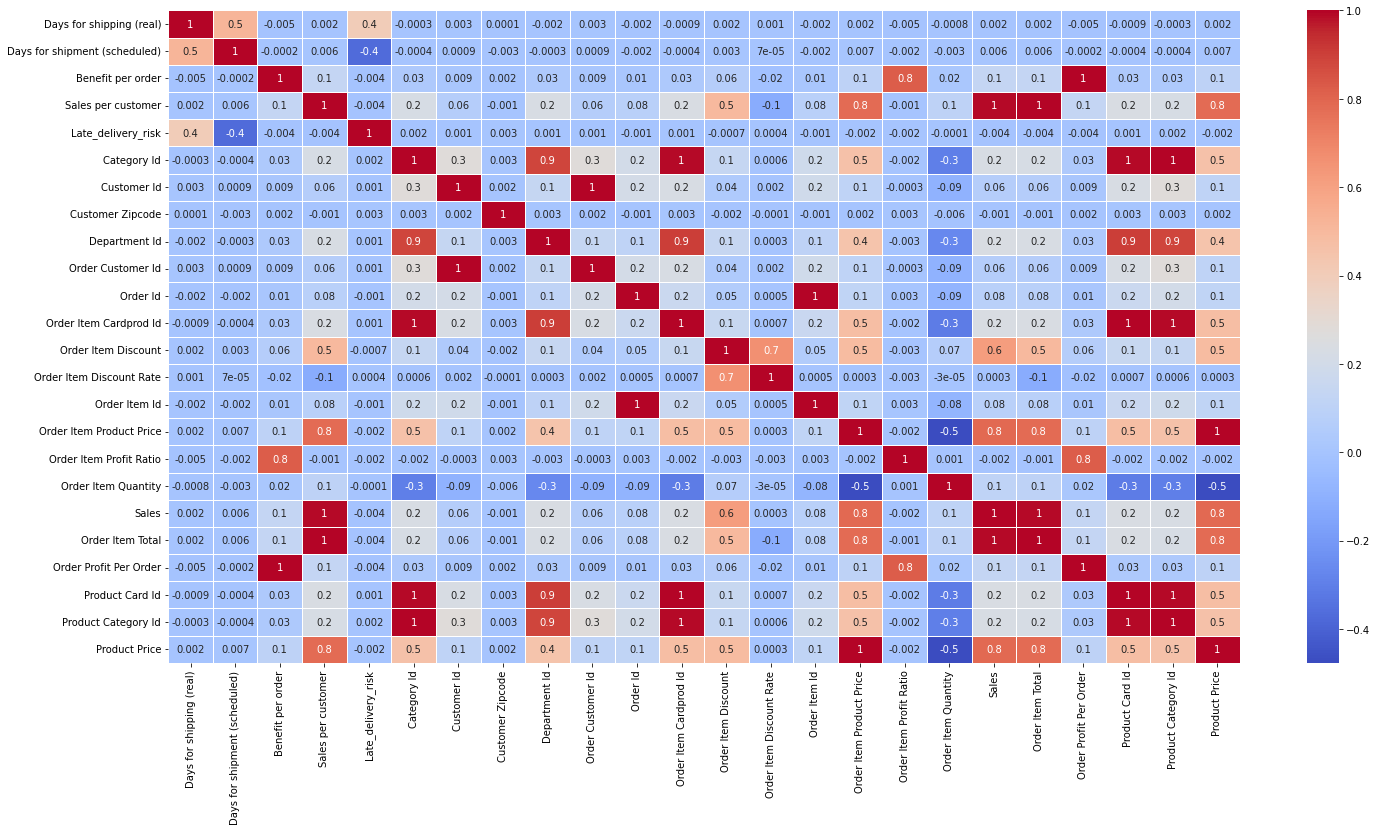

In [12]:
# to find important features - correlation matrix

fig, ax = plt.subplots(figsize=(24,12))         # figsize
sns.heatmap(data.corr(),annot=True,linewidths=.5,fmt='.1g',cmap= 'coolwarm') # Heatmap for correlation matrix

# product price has high correlation with sales and order item

In [13]:
# HIGH CORRELATION
# benefit per order - order profit per order
# sales per customer - sales - order item total
# category id - department id - order item cardprod id - product category id - product card id
# customer id - order customer id
# order item product price - product price

In [14]:
# dropping unwanted columns

drop_cols = ['Order Profit Per Order', 'Sales per customer', 'Order Item Total', 'Department Id', 
             'Order Item Cardprod Id', 'Product Category Id', 'Product Card Id', 'Order Customer Id', 
             'Order Item Product Price']
data.drop(columns = drop_cols,  inplace = True)

In [15]:
data.shape

# 34 columns left

(180519, 34)

In [16]:
data['order_year']= pd.DatetimeIndex(data['order date (DateOrders)']).year
data['order_month'] = pd.DatetimeIndex(data['order date (DateOrders)']).month
data['order_week_day'] = pd.DatetimeIndex(data['order date (DateOrders)']).weekday
data['order_hour'] = pd.DatetimeIndex(data['order date (DateOrders)']).hour
data['order_month_year'] = pd.to_datetime(data['order date (DateOrders)']).dt.to_period('M')

# DATA VISUALIZATION

<Axes: title={'center': 'Total sales for all regions'}, xlabel='Order Region'>

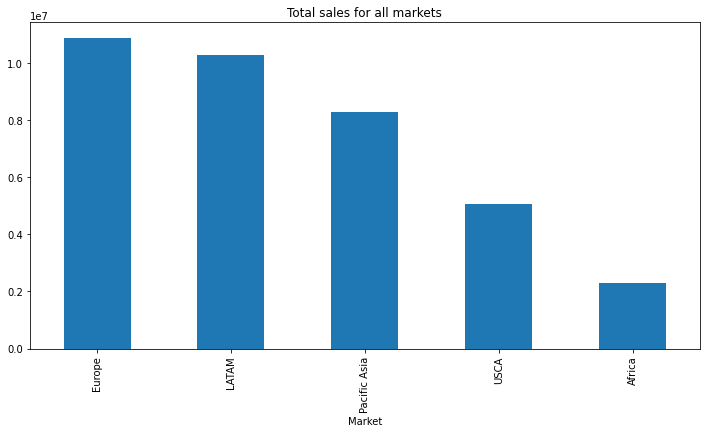

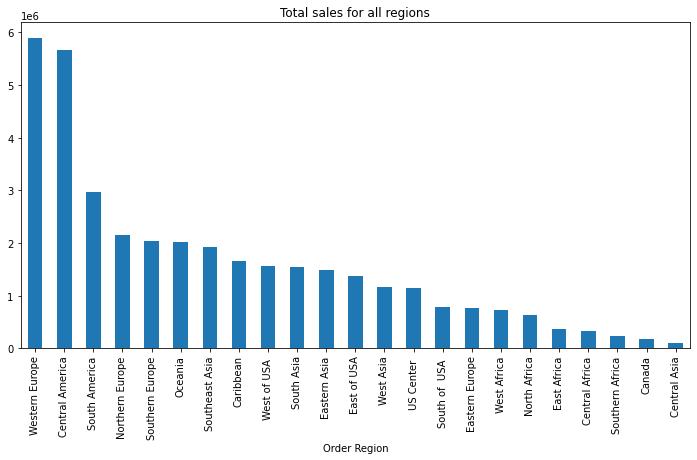

In [17]:
# which region has most sales

market = data.groupby('Market')
region = data.groupby('Order Region')
plt.figure(1)
market['Sales'].sum().sort_values(ascending=False).plot.bar(figsize=(12,6), title="Total sales for all markets")
plt.figure(2)
region['Sales'].sum().sort_values(ascending=False).plot.bar(figsize=(12,6), title="Total sales for all regions")

In [18]:
# EU has most number of sales -  Africa least
# Western EU and Central America - most sales

<Axes: title={'center': 'Average price'}, xlabel='Category Name'>

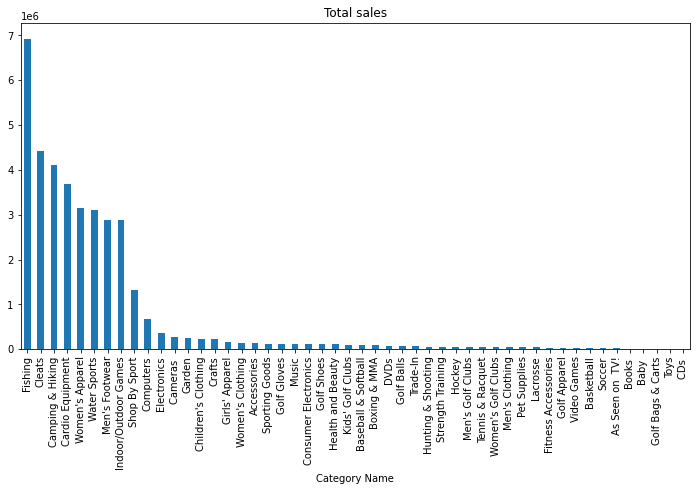

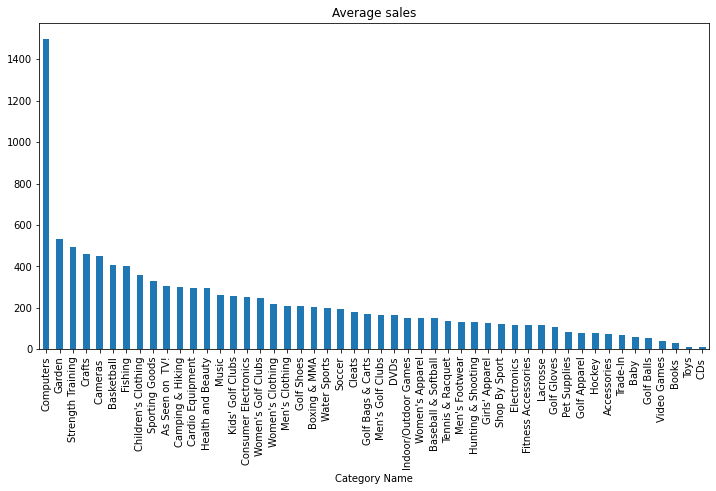

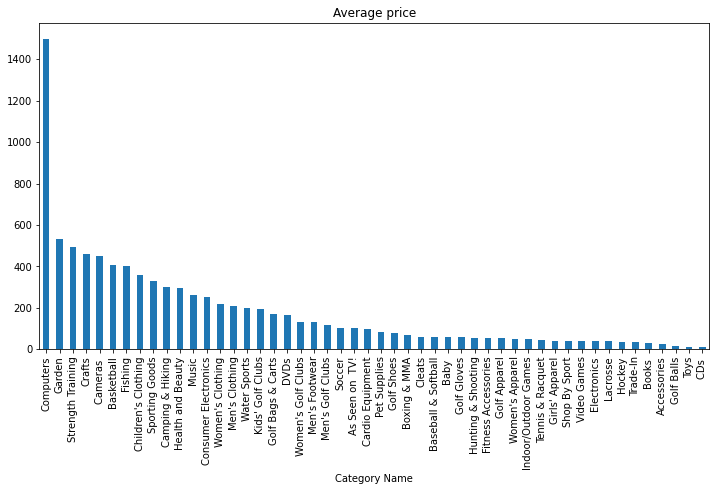

In [19]:
# which category has highest sales

#Grouping all categories
cat = data.groupby('Category Name')
plt.figure(1)
# Total sum of sales for all categories
cat['Sales'].sum().sort_values(ascending=False).plot.bar(figsize=(12,6), title="Total sales")
# Mean sales for all categories
plt.figure(2)
cat['Sales'].mean().sort_values(ascending=False).plot.bar(figsize=(12,6), title="Average sales")
plt.figure(3)
# Mean prices for all categories
cat['Product Price'].mean().sort_values(ascending=False).plot.bar(figsize=(12,6), title="Average price")

In [20]:
#  fishing category had most number of sales
# top 7 products with highest price on average are the most sold products on average - computers


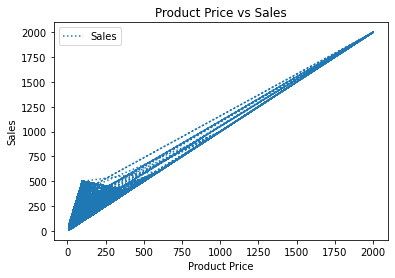

In [21]:
# high correlation between price and sales
data.plot(x='Product Price', y='Sales',linestyle='dotted',
     markerfacecolor='blue', markersize=12) 
plt.title('Product Price vs Sales')#title
plt.xlabel('Product Price')  # X-axis title
plt.ylabel('Sales') # Y=axis title
plt.show()

In [22]:
# linear relation

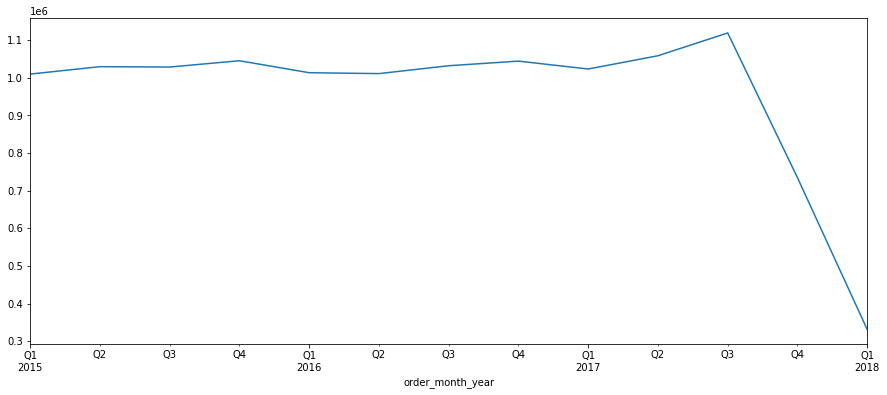

In [23]:
# time of sales

quater= data.groupby('order_month_year')
quartersales=quater['Sales'].sum().resample('Q').mean().plot(figsize=(15,6))

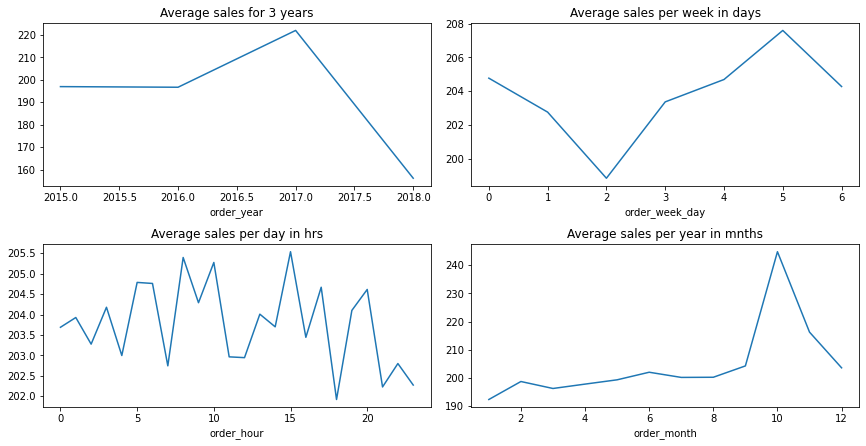

In [24]:
plt.figure(figsize=(10,12))
plt.subplot(4, 2, 1)
quater= data.groupby('order_year')
quater['Sales'].mean().plot(figsize=(12,12),title='Average sales for 3 years')
plt.subplot(4, 2, 2)
days=data.groupby("order_week_day")
days['Sales'].mean().plot(figsize=(12,12),title='Average sales per week in days')
plt.subplot(4, 2, 3)
hrs=data.groupby("order_hour")
hrs['Sales'].mean().plot(figsize=(12,12),title='Average sales per day in hrs')
plt.subplot(4, 2, 4)
mnth=data.groupby("order_month")
mnth['Sales'].mean().plot(figsize=(12,12),title='Average sales per year in mnths')
plt.tight_layout()
plt.show()

In [25]:
# type of payments

data['Type'].unique()

array(['CASH', 'PAYMENT', 'DEBIT', 'TRANSFER'], dtype=object)

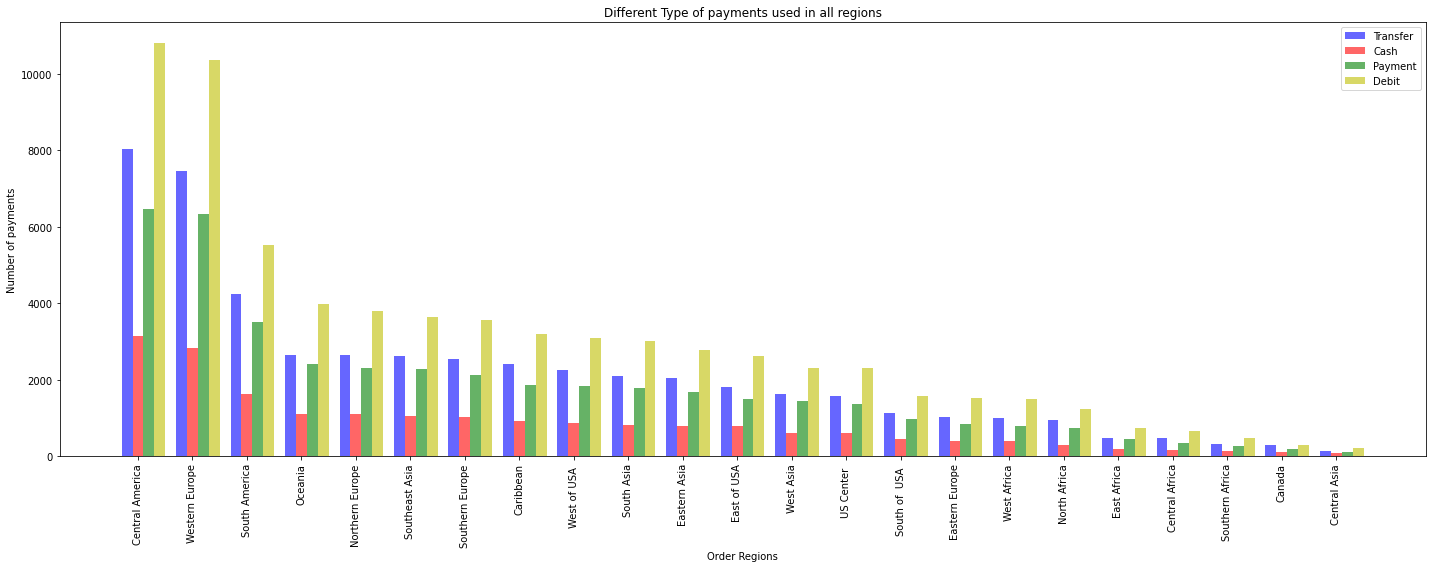

In [26]:
#xyz = data.groupby('Type')
xyz1 = data[(data['Type'] == 'TRANSFER')]
xyz2= data[(data['Type'] == 'CASH')]
xyz3= data[(data['Type'] == 'PAYMENT')]
xyz4= data[(data['Type'] == 'DEBIT')]
count1=xyz1['Order Region'].value_counts()
count2=xyz2['Order Region'].value_counts()
count3=xyz3['Order Region'].value_counts()
count4=xyz4['Order Region'].value_counts()
names=data['Order Region'].value_counts().keys()
n_groups=23
fig,ax = plt.subplots(figsize=(20,8))
index=np.arange(n_groups)
bar_width=0.2
opacity=0.6
type1=plt.bar(index,count1,bar_width,alpha=opacity,color='b',label='Transfer')
type2=plt.bar(index+bar_width,count2,bar_width,alpha=opacity,color='r',label='Cash')
type3=plt.bar(index+bar_width+bar_width,count3,bar_width,alpha=opacity,color='g',label='Payment')
type4=plt.bar(index+bar_width+bar_width+bar_width,count4,bar_width,alpha=opacity,color='y',label='Debit')
plt.xlabel('Order Regions')
plt.ylabel('Number of payments')
plt.title('Different Type of payments used in all regions')
plt.legend()
plt.xticks(index+bar_width,names,rotation=90)
plt.tight_layout()
plt.show()

Total revenue lost with orders -3883547.345768667


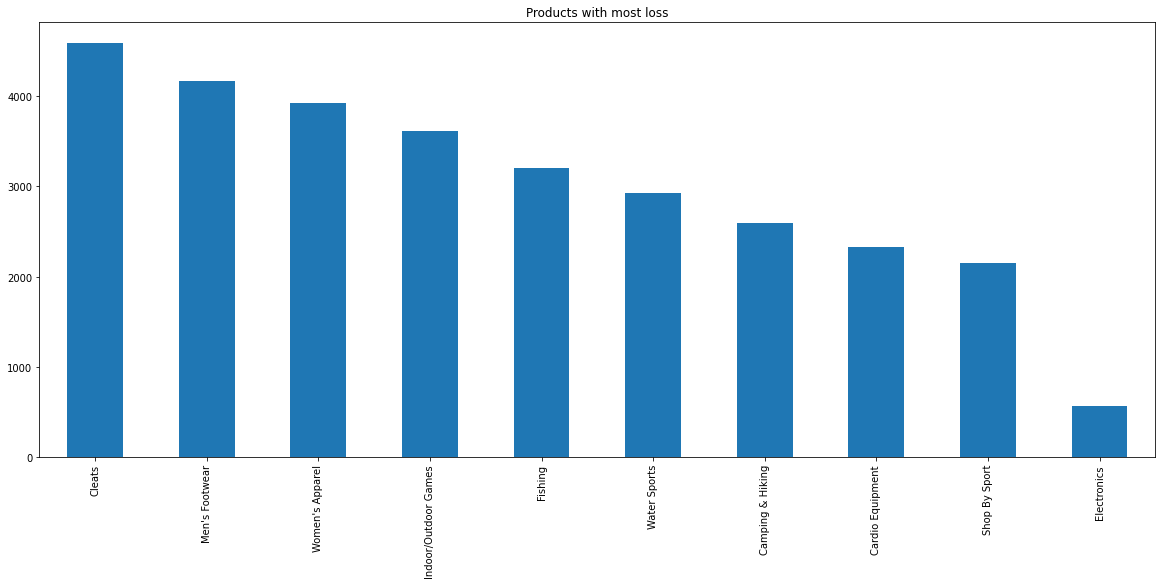

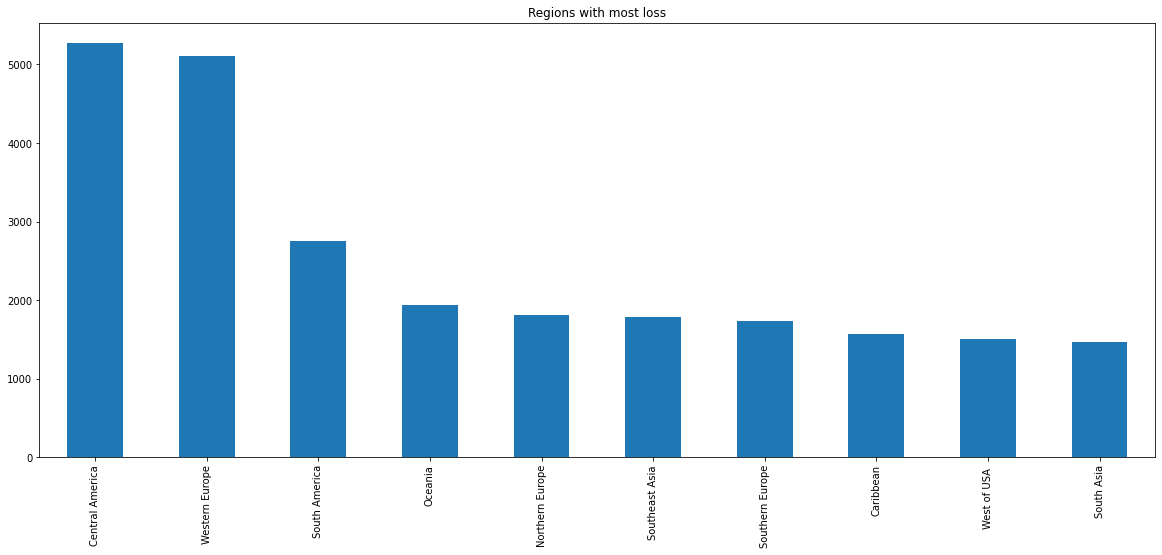

In [27]:
# products with most loss

loss = data[(data['Benefit per order']<0)]
#Plotting top 10 products with most loss
plt.figure(1)
loss['Category Name'].value_counts().nlargest(10).plot.bar(figsize=(20,8), title="Products with most loss")
plt.figure(2)
loss['Order Region'].value_counts().nlargest(10).plot.bar(figsize=(20,8), title="Regions with most loss")
#Sum of total sales which are lost
print('Total revenue lost with orders',loss['Benefit per order'].sum())

In [28]:
#Checking type of payment used to conduct fraud other than Transfer
xyz = data[(data['Type'] != 'TRANSFER')&(data['Order Status'] == 'SUSPECTED_FRAUD')]
xyz['Order Region'].value_counts()

# only TRANSFER

Series([], Name: Order Region, dtype: int64)

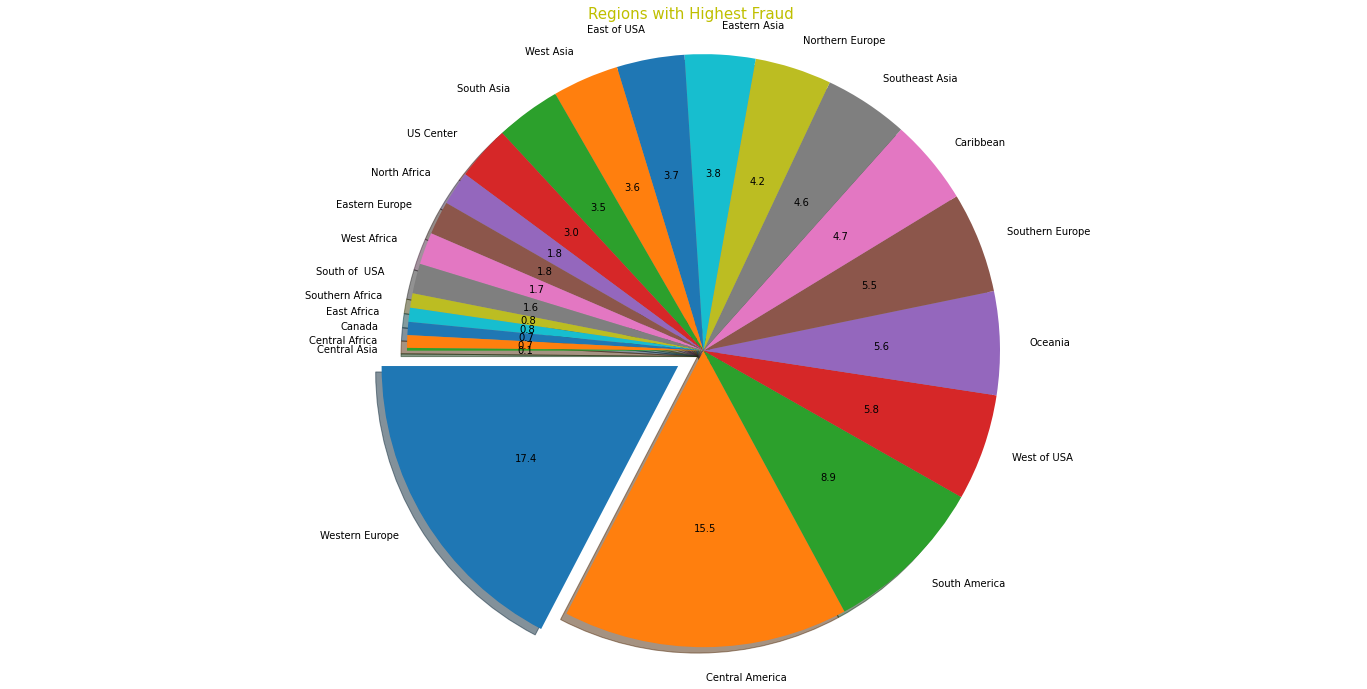

In [29]:
# which region?
high_fraud = data[(data['Order Status'] == 'SUSPECTED_FRAUD') & (data['Type'] == 'TRANSFER')]#separating orders with suspected fraud
#Plotting pie chart with respect to order region
fraud=high_fraud['Order Region'].value_counts().plot.pie(figsize=(24,12),
                                                  startangle=180, explode=(0.1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0),autopct='%.1f',shadow=True,)
plt.title("Regions with Highest Fraud",size=15,color='y') # Plotting title
plt.ylabel(" ")
fraud.axis('equal') 
plt.show()

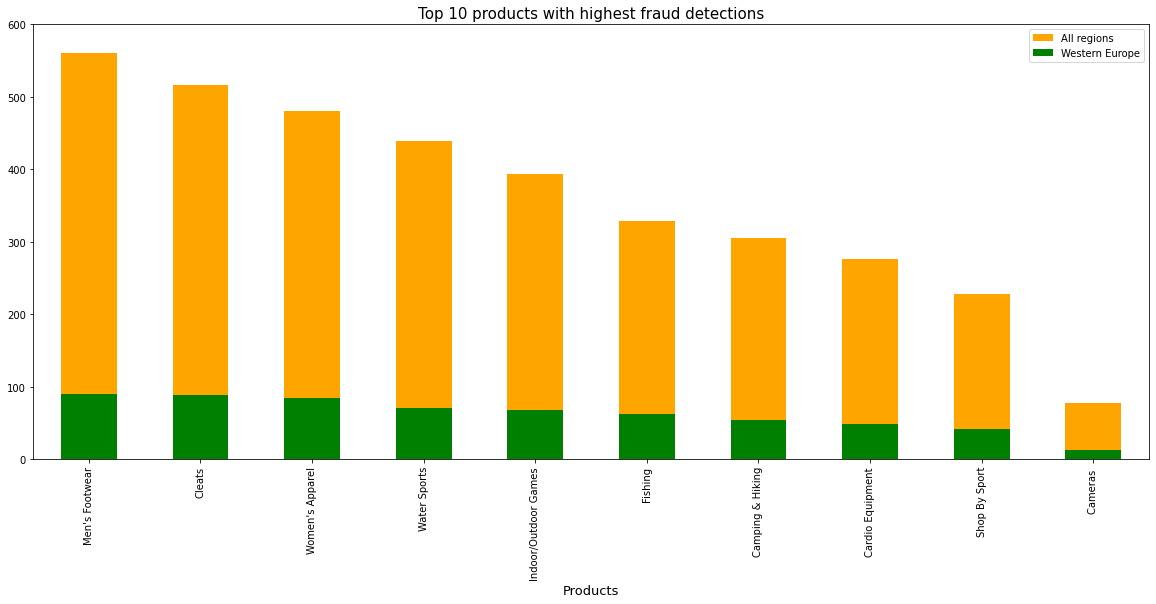

In [30]:
# which products?
high_fraud1 = data[(data['Order Status'] == 'SUSPECTED_FRAUD')] # 
high_fraud2 = data[(data['Order Status'] == 'SUSPECTED_FRAUD') &(data['Order Region'] == 'Western Europe')]
#Plotting bar chart for top 10 most suspected fraud department in all regions
fraud1=high_fraud1['Category Name'].value_counts().nlargest(10).plot.bar(figsize=(20,8), title="Fraud Category",color='orange')
#Plotting bar chart for top 10 most suspected fraud department in Western Europe
fraud2=high_fraud2['Category Name'].value_counts().nlargest(10).plot.bar(figsize=(20,8), title="Fraud product in Western Europe",color='green')
plt.legend(["All regions", "Western Europe"])
plt.title("Top 10 products with highest fraud detections", size=15)
plt.xlabel("Products", size=13)
plt.ylim(0,600)
plt.show()

<Axes: title={'center': 'Top 10 Highest Fraud Customers'}>

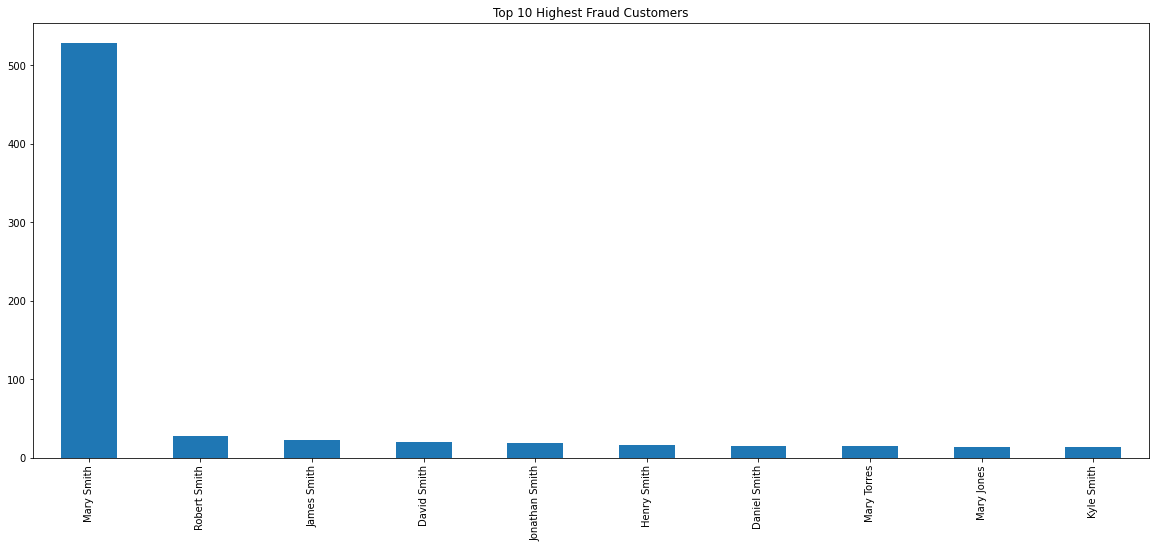

In [31]:
# which customers?

#Filtering out suspected fruad orders
cus = data[(data['Order Status'] == 'SUSPECTED_FRAUD')] 
#Top 10 customers with most fraud
cus['Customer Full Name'].value_counts().nlargest(10).plot.bar(figsize=(20,8), title="Top 10 Highest Fraud Customers")

In [32]:
# amount of Mary Smith

#Filtering orders of mary smith with suspected fraud
amount = data[(data['Customer Full Name'] == 'Mary Smith')&(data['Order Status'] == 'SUSPECTED_FRAUD')]
#Plotting bar chart for top 10 most suspected fraud customers
amount['Sales'].sum()

102491.66191044

<Axes: title={'center': 'Top 10 products with most late deliveries'}>

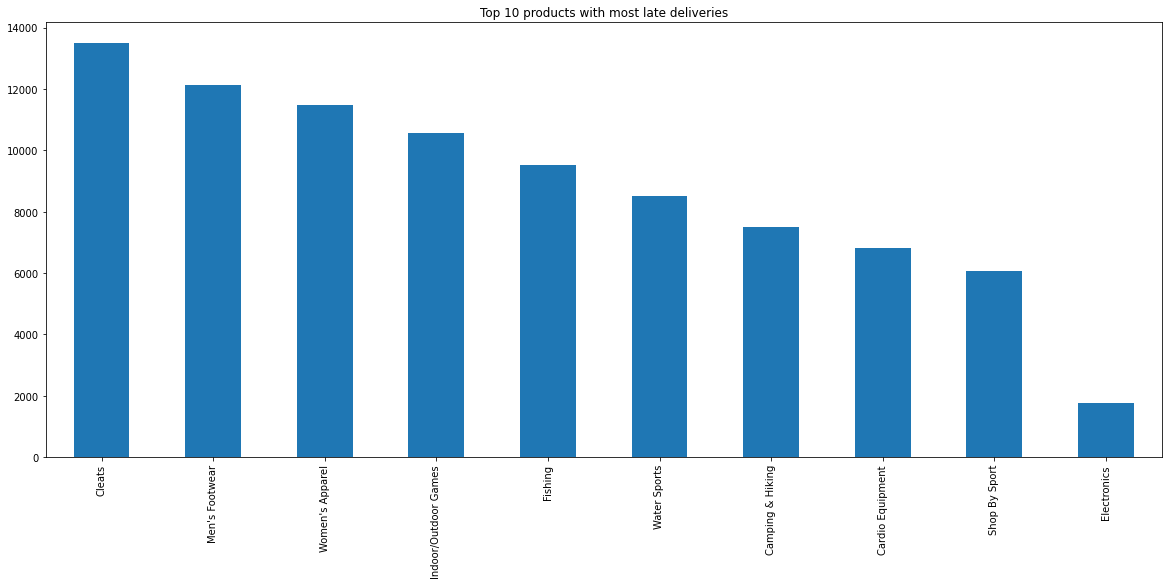

In [33]:
# late delivery catgories

#Filtering columns with late delivery status
late_delivery = data[(data['Delivery Status'] == 'Late delivery')]
#Top 10 products with most late deliveries
late_delivery['Category Name'].value_counts().nlargest(10).plot.bar(figsize=(20,8), title="Top 10 products with most late deliveries")

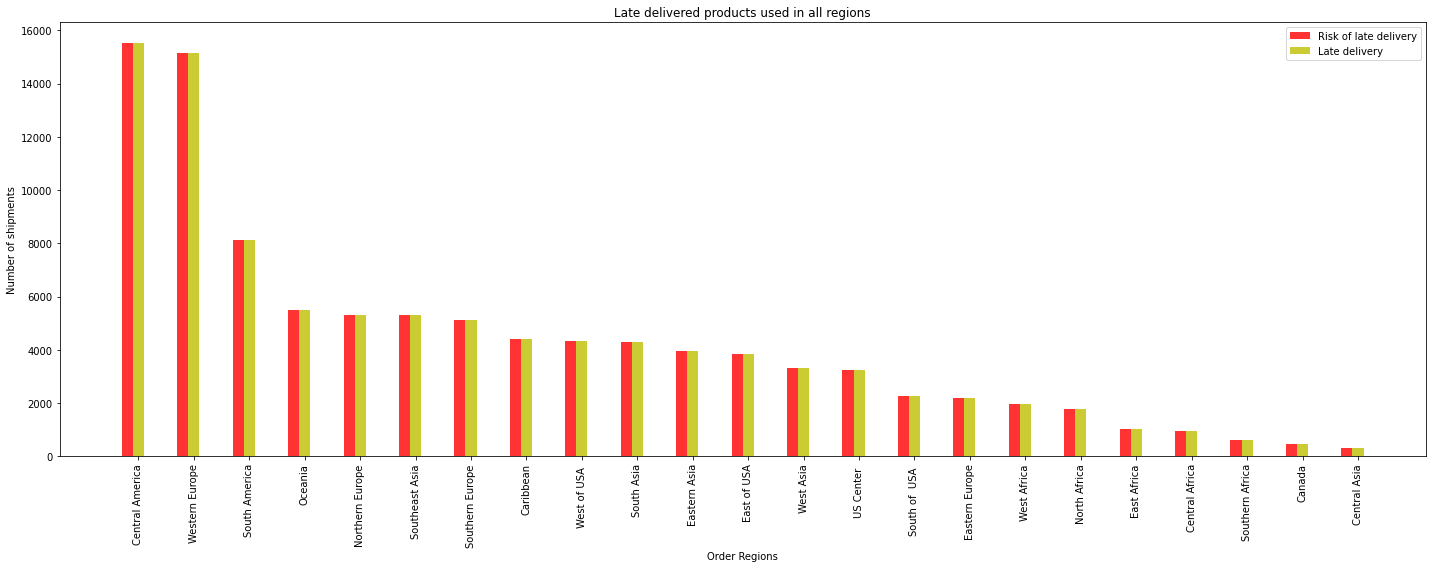

In [34]:
# late delivery risk compared to actual late delivery

#Filtering orders with late delivery risk
xyz1 = data[(data['Late_delivery_risk'] == 1)]
#Filtering late delivered orders
xyz2 = data[(data['Delivery Status'] == 'Late delivery')]
count1=xyz1['Order Region'].value_counts()
count2=xyz2['Order Region'].value_counts()
#Index names
names=data['Order Region'].value_counts().keys()
n_groups=23
fig,ax = plt.subplots(figsize=(20,8)) #Figure size
index=np.arange(n_groups)
bar_width=0.2
opacity=0.8
type1=plt.bar(index,count1,bar_width,alpha=opacity,color='r',label='Risk of late delivery')
type2=plt.bar(index+bar_width,count2,bar_width,alpha=opacity,color='y',label='Late delivery')
plt.xlabel('Order Regions')
plt.ylabel('Number of shipments')
plt.title('Late delivered products used in all regions')
plt.legend()
plt.xticks(index+bar_width,names,rotation=90)
plt.tight_layout()
plt.show()

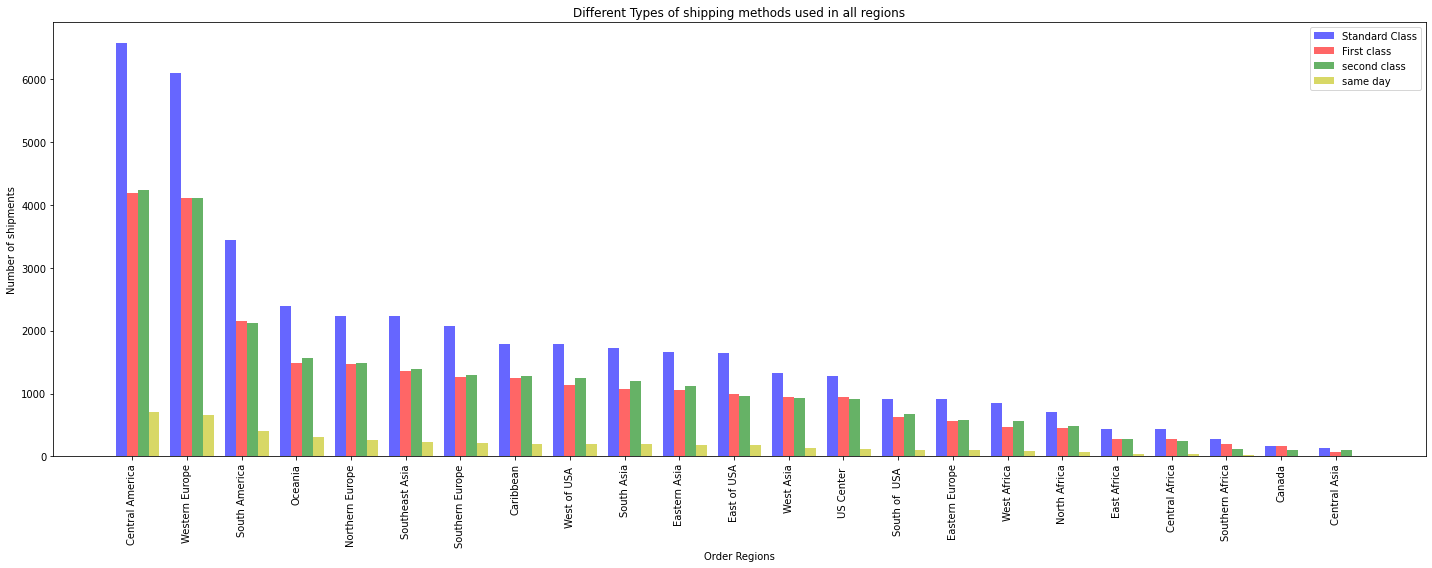

In [35]:
# types of shipping methods

#Filtering late delivery orders with standard class shipping
xyz1 = data[(data['Delivery Status'] == 'Late delivery') & (data['Shipping Mode'] == 'Standard Class')]
#Filtering late delivery orders with first class shipping
xyz2 = data[(data['Delivery Status'] == 'Late delivery') & (data['Shipping Mode'] == 'First Class')]
#Filtering late delivery orders with second class shipping
xyz3 = data[(data['Delivery Status'] == 'Late delivery') & (data['Shipping Mode'] == 'Second Class')]
#Filtering late delivery orders with same day shipping
xyz4 = data[(data['Delivery Status'] == 'Late delivery') & (data['Shipping Mode'] == 'Same Day')]
#Counting total values
count1=xyz1['Order Region'].value_counts()
count2=xyz2['Order Region'].value_counts()
count3=xyz3['Order Region'].value_counts()
count4=xyz4['Order Region'].value_counts()
#Index names
names=data['Order Region'].value_counts().keys()
n_groups=23
fig,ax = plt.subplots(figsize=(20,8))
index=np.arange(n_groups)
bar_width=0.2
opacity=0.6
type1=plt.bar(index,count1,bar_width,alpha=opacity,color='b',label='Standard Class')
type2=plt.bar(index+bar_width,count2,bar_width,alpha=opacity,color='r',label='First class')
type3=plt.bar(index+bar_width+bar_width,count3,bar_width,alpha=opacity,color='g',label='second class')
type4=plt.bar(index+bar_width+bar_width+bar_width,count4,bar_width,alpha=opacity,color='y',label='same day')
plt.xlabel('Order Regions')
plt.ylabel('Number of shipments')
plt.title('Different Types of shipping methods used in all regions')
plt.legend()
plt.xticks(index+bar_width,names,rotation=90)
plt.tight_layout()
plt.show()

# Baseline and ML models

In [36]:
# --- DELAY: columns to drop
delay_drop_cols = [
    'Late_delivery_risk',
    'Order Item Quantity',
    'order date (DateOrders)',
    'shipping date (DateOrders)',
    'order_month_year',
    'Delivery Status',
    'Days for shipping (real)',
    'Days for shipment (scheduled)',
    'Benefit per order',
    'Order Item Profit Ratio',
    'Order Item Discount',
    'Order Item Discount Rate',
    'Sales',
    'Product Price',
    'Customer Id',
    'Order Id',
    'Order Item Id',
    'Category Id',
    'Customer Full Name',
    'Order Status',
]

In [37]:
# --- DELAY: columns to encode
delay_encode_cols = [
    'Shipping Mode', 'Market', 'Order Region',
    'Category Name', 'Department Name',
    'Customer Segment', 'Type',
]

In [38]:
# --- DELAY: context columns saved for SAP export ---
delay_context_cols = [
    'Order Region', 'Category Name',
    'Shipping Mode', 'Market', 'Product Name',
]

In [39]:
# --- DEMAND: only needs category encoding after aggregation ---
demand_encode_cols  = ['Category Name']
demand_context_cols = ['Category Name', 'order_year', 'order_month']

In [40]:
# DEMAND: Aggregate to monthly category level
demand_agg = data.groupby(
    ['order_year', 'order_month', 'Category Name']
).agg(
    total_demand = ('Order Item Quantity', 'sum'),
    total_sales  = ('Sales', 'sum'),
    avg_price    = ('Product Price', 'mean'),
    order_count  = ('Order Id', 'count'),
).reset_index()

print("Demand aggregated shape:", demand_agg.shape)
print(demand_agg.head())

Demand aggregated shape: (853, 7)
   order_year  order_month        Category Name  total_demand    total_sales  \
0        2015            1          Accessories           154    3848.459970   
1        2015            1  Baseball & Softball            68    3629.320095   
2        2015            1         Boxing & MMA            24    1319.280029   
3        2015            1     Camping & Hiking           415  124491.704565   
4        2015            1     Cardio Equipment          1188  115288.619765   

    avg_price  order_count  
0   24.990000           56  
1   53.740002           20  
2   54.970001            8  
3  299.980011          415  
4   97.136689          417  


In [57]:
demand_encoded = pd.get_dummies(demand_agg,
                                 columns=demand_encode_cols)

y_demand = demand_encoded['total_demand']
X_demand = demand_encoded.drop(columns=['total_demand', 'total_sales'])

print("X_demand shape:", X_demand.shape)

X_demand shape: (853, 54)


In [59]:
print("Demand features:")
for col in X_demand.columns.tolist():
    print(f"  {col}: {X_demand[col].dtype}")

Demand features:
  order_year: int64
  order_month: int64
  avg_price: float64
  order_count: int64
  Category Name_Accessories: uint8
  Category Name_As Seen on  TV!: uint8
  Category Name_Baby : uint8
  Category Name_Baseball & Softball: uint8
  Category Name_Basketball: uint8
  Category Name_Books : uint8
  Category Name_Boxing & MMA: uint8
  Category Name_CDs : uint8
  Category Name_Cameras : uint8
  Category Name_Camping & Hiking: uint8
  Category Name_Cardio Equipment: uint8
  Category Name_Children's Clothing: uint8
  Category Name_Cleats: uint8
  Category Name_Computers: uint8
  Category Name_Consumer Electronics: uint8
  Category Name_Crafts: uint8
  Category Name_DVDs: uint8
  Category Name_Electronics: uint8
  Category Name_Fishing: uint8
  Category Name_Fitness Accessories: uint8
  Category Name_Garden: uint8
  Category Name_Girls' Apparel: uint8
  Category Name_Golf Apparel: uint8
  Category Name_Golf Bags & Carts: uint8
  Category Name_Golf Balls: uint8
  Category Name_Go

In [60]:
X_demand

,order_year,order_month,avg_price,order_count,Category Name_Accessories,Category Name_As Seen on TV!,Category Name_Baby,Category Name_Baseball & Softball,Category Name_Basketball,Category Name_Books,...,Category Name_Sporting Goods,Category Name_Strength Training,Category Name_Tennis & Racquet,Category Name_Toys,Category Name_Trade-In,Category Name_Video Games,Category Name_Water Sports,Category Name_Women's Apparel,Category Name_Women's Clothing,Category Name_Women's Golf Clubs
0,2015,1,24.990000,56,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2015,1,53.740002,20,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2015,1,54.970001,8,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,2015,1,299.980011,415,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2015,1,97.136689,417,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
848,2018,1,84.400002,246,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
849,2018,1,327.750000,212,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
850,2018,1,11.540000,276,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
851,2018,1,39.750000,610,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0


In [58]:
# DELAY

# Save context before any dropping
delay_context_data = data[delay_context_cols].copy()

# Drop
data_model = data.drop(
    columns=[c for c in delay_drop_cols if c in data.columns],
    errors='ignore'
)

# Encode categoricals
encode_present = [c for c in delay_encode_cols if c in data_model.columns]
data_encoded   = pd.get_dummies(data_model,
                                 columns=encode_present,
                                 drop_first=True)

# Keep only numeric/bool
X_delay = data_encoded.select_dtypes(include=['number', 'bool'])
y_delay = data['Late_delivery_risk']

print("X_delay shape:", X_delay.shape)

X_delay shape: (180519, 98)


In [61]:
print("Delay features:")
for col in X_delay.columns.tolist():
    print(f"  {col}: {X_delay[col].dtype}")

Delay features:
  Customer Zipcode: float64
  order_year: int64
  order_month: int64
  order_week_day: int64
  order_hour: int64
  Shipping Mode_Same Day: uint8
  Shipping Mode_Second Class: uint8
  Shipping Mode_Standard Class: uint8
  Market_Europe: uint8
  Market_LATAM: uint8
  Market_Pacific Asia: uint8
  Market_USCA: uint8
  Order Region_Caribbean: uint8
  Order Region_Central Africa: uint8
  Order Region_Central America: uint8
  Order Region_Central Asia: uint8
  Order Region_East Africa: uint8
  Order Region_East of USA: uint8
  Order Region_Eastern Asia: uint8
  Order Region_Eastern Europe: uint8
  Order Region_North Africa: uint8
  Order Region_Northern Europe: uint8
  Order Region_Oceania: uint8
  Order Region_South America: uint8
  Order Region_South Asia: uint8
  Order Region_South of  USA : uint8
  Order Region_Southeast Asia: uint8
  Order Region_Southern Africa: uint8
  Order Region_Southern Europe: uint8
  Order Region_US Center : uint8
  Order Region_West Africa: uint8

In [62]:
X_delay

,Customer Zipcode,order_year,order_month,order_week_day,order_hour,Shipping Mode_Same Day,Shipping Mode_Second Class,Shipping Mode_Standard Class,Market_Europe,Market_LATAM,...,Department Name_Golf,Department Name_Health and Beauty,Department Name_Outdoors,Department Name_Pet Shop,Department Name_Technology,Customer Segment_Corporate,Customer Segment_Home Office,Type_DEBIT,Type_PAYMENT,Type_TRANSFER
33833,28601.0,2015,1,3,0,0,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
77011,60625.0,2015,1,3,0,0,0,1,0,1,...,0,0,0,0,0,0,0,0,1,0
109322,60625.0,2015,1,3,0,0,0,1,0,1,...,1,0,0,0,0,0,0,0,1,0
87884,60625.0,2015,1,3,0,0,0,1,0,1,...,0,0,0,0,0,0,0,0,1,0
114915,78240.0,2015,1,3,1,0,0,1,0,1,...,0,0,0,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
160537,725.0,2018,1,2,22,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,1
93905,60544.0,2018,1,2,22,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
0,725.0,2018,1,2,22,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
52147,60402.0,2018,1,2,23,0,0,1,0,0,...,0,0,0,0,0,1,0,0,1,0


In [43]:
from sklearn.model_selection import train_test_split

# Demand split
X_demand_train, X_demand_test, \
y_demand_train, y_demand_test = train_test_split(
    X_demand, y_demand,
    test_size=0.2, random_state=42
)

# Delay split
X_delay_train, X_delay_test, \
y_delay_train, y_delay_test = train_test_split(
    X_delay, y_delay,
    test_size=0.2, random_state=42
)

print("Demand — Train:", X_demand_train.shape[0], "| Test:", X_demand_test.shape[0])
print("Delay  — Train:", X_delay_train.shape[0],  "| Test:", X_delay_test.shape[0])

Demand — Train: 682 | Test: 171
Delay  — Train: 144415 | Test: 36104


Baseline Models

In [44]:
from sklearn.linear_model import PoissonRegressor, LogisticRegression

# DEMAND

baseline_demand = PoissonRegressor()
baseline_demand.fit(X_demand_train, y_demand_train)
pred_demand_baseline = baseline_demand.predict(X_demand_test)

# DELAY

baseline_delay = LogisticRegression(max_iter=1000)
baseline_delay.fit(X_delay_train, y_delay_train)
pred_delay_baseline = baseline_delay.predict(X_delay_test)

ML models

In [45]:
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

# DEMAND

demand_model = RandomForestRegressor(n_estimators=100, random_state=42)
demand_model.fit(X_demand_train, y_demand_train)
pred_demand_ml = demand_model.predict(X_demand_test)

# DELAY

delay_model = RandomForestClassifier(n_estimators=100, random_state=42)
delay_model.fit(X_delay_train, y_delay_train)
pred_delay_ml  = delay_model.predict(X_delay_test)
delay_risk     = delay_model.predict_proba(X_delay_test)[:, 1]  # probability

In [46]:
!pip install xgboost

You should consider upgrading via the 'C:\Users\Csabi\AppData\Local\Programs\Python\Python39\python.exe -m pip install --upgrade pip' command.


In [47]:
from xgboost import XGBRegressor, XGBClassifier

# DEMAND

xgb_demand = XGBRegressor(n_estimators=100, random_state=42, verbosity=0)
xgb_demand.fit(X_demand_train, y_demand_train)
pred_demand_xgb = xgb_demand.predict(X_demand_test)

# DELAY

xgb_delay = XGBClassifier(n_estimators=100, random_state=42,
                           use_label_encoder=False, eval_metric='logloss')
xgb_delay.fit(X_delay_train, y_delay_train)
pred_delay_xgb  = xgb_delay.predict(X_delay_test)
delay_risk_xgb  = xgb_delay.predict_proba(X_delay_test)[:, 1]

Evaluation

In [48]:
from sklearn.metrics import (mean_absolute_error, accuracy_score,
                             confusion_matrix, classification_report)
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# DEMAND COMPARISON

mae_baseline = mean_absolute_error(y_demand_test, pred_demand_baseline)
mae_rf       = mean_absolute_error(y_demand_test, pred_demand_ml)
mae_xgb      = mean_absolute_error(y_demand_test, pred_demand_xgb)

print("=== Demand Forecasting (MAE — lower is better) ===")
print(f"  Poisson Baseline : {mae_baseline:.3f}")
print(f"  Random Forest    : {mae_rf:.3f}")
print(f"  XGBoost          : {mae_xgb:.3f}")

# DELAY COMPARISON

acc_baseline = accuracy_score(y_delay_test, pred_delay_baseline)
acc_rf       = accuracy_score(y_delay_test, pred_delay_ml)
acc_xgb      = accuracy_score(y_delay_test, pred_delay_xgb)

print("\n=== Late Delivery Prediction (Accuracy — higher is better) ===")
print(f"  Logistic Baseline : {acc_baseline:.3f}")
print(f"  Random Forest     : {acc_rf:.3f}")
print(f"  XGBoost           : {acc_xgb:.3f}")

=== Demand Forecasting (MAE — lower is better) ===
  Poisson Baseline : 520.727
  Random Forest    : 19.890
  XGBoost          : 23.161

=== Late Delivery Prediction (Accuracy — higher is better) ===
  Logistic Baseline : 0.705
  Random Forest     : 0.800
  XGBoost           : 0.739


In [49]:
# --- Summary table ---
summary = pd.DataFrame({
    "Model":          ["Baseline", "Random Forest", "XGBoost"],
    "Demand MAE":     [mae_baseline, mae_rf, mae_xgb],
    "Delay Accuracy": [acc_baseline, acc_rf, acc_xgb]
})
print("\n", summary.to_string(index=False))


         Model  Demand MAE  Delay Accuracy
     Baseline  520.727290        0.705379
Random Forest   19.889591        0.800438
      XGBoost   23.160940        0.738893


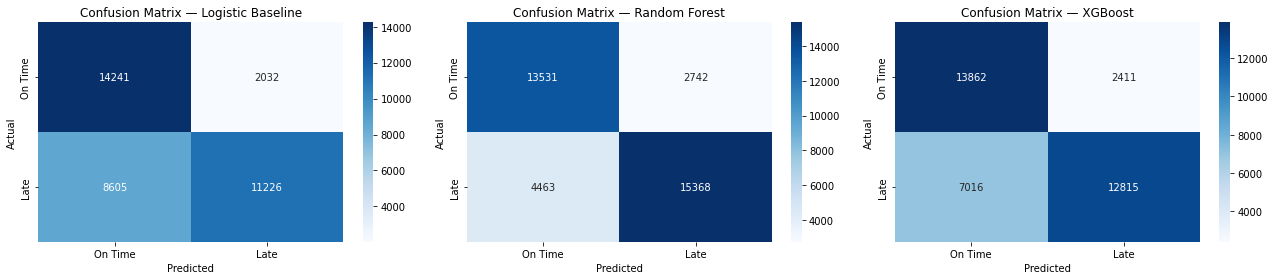


--- Logistic Baseline ---
              precision    recall  f1-score   support

     On Time       0.62      0.88      0.73     16273
        Late       0.85      0.57      0.68     19831

    accuracy                           0.71     36104
   macro avg       0.74      0.72      0.70     36104
weighted avg       0.75      0.71      0.70     36104


--- Random Forest ---
              precision    recall  f1-score   support

     On Time       0.75      0.83      0.79     16273
        Late       0.85      0.77      0.81     19831

    accuracy                           0.80     36104
   macro avg       0.80      0.80      0.80     36104
weighted avg       0.81      0.80      0.80     36104


--- XGBoost ---
              precision    recall  f1-score   support

     On Time       0.66      0.85      0.75     16273
        Late       0.84      0.65      0.73     19831

    accuracy                           0.74     36104
   macro avg       0.75      0.75      0.74     36104
weighte

In [50]:
# --- Confusion matrices (all 3 models) ---
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

for ax, preds, title in zip(axes,
                             [pred_delay_baseline, pred_delay_ml, pred_delay_xgb],
                             ["Logistic Baseline", "Random Forest", "XGBoost"]):
    cm = confusion_matrix(y_delay_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['On Time', 'Late'],
                yticklabels=['On Time', 'Late'])
    ax.set_title(f'Confusion Matrix — {title}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

# --- Classification reports (all 3 models) ---
for preds, name in [(pred_delay_baseline, "Logistic Baseline"),
                    (pred_delay_ml,       "Random Forest"),
                    (pred_delay_xgb,      "XGBoost")]:
    print(f"\n--- {name} ---")
    print(classification_report(y_delay_test, preds,
                                target_names=['On Time', 'Late']))

In [51]:

# SELECT BEST MODELS

best_demand_model = demand_model if mae_rf  <= mae_xgb else xgb_demand
best_delay_model  = delay_model  if acc_rf  >= acc_xgb else xgb_delay
best_demand_preds = pred_demand_ml  if mae_rf <= mae_xgb else pred_demand_xgb
best_delay_preds  = pred_delay_ml   if acc_rf >= acc_xgb else pred_delay_xgb
best_delay_risk   = delay_risk   if acc_rf >= acc_xgb else delay_risk_xgb

best_demand_name = "Random Forest" if mae_rf  <= mae_xgb else "XGBoost"
best_delay_name  = "Random Forest" if acc_rf  >= acc_xgb else "XGBoost"

print(f"Best demand model : {best_demand_name}")
print(f"Best delay model  : {best_delay_name}")

Best demand model : Random Forest
Best delay model  : Random Forest


In [52]:

# DECISION SUPPORT LAYER


# Calculate average demand per category (its own baseline)
category_avg = demand_agg.groupby('Category Name')['total_demand'].mean()

# Attach category average to results
demand_results = demand_agg.copy()
demand_results["predicted_demand"] = best_demand_model.predict(X_demand)
demand_results["category_avg"]     = demand_results["Category Name"].map(category_avg)

def inventory_decision(row):
    if row["predicted_demand"] > row["category_avg"] * 1.2:
        return "Increase Stock"
    elif row["predicted_demand"] < row["category_avg"] * 0.8:
        return "Reduce Stock"
    else:
        return "Maintain"

demand_results["inventory_decision"] = demand_results.apply(
    inventory_decision, axis=1
)

print(demand_results[["order_year", "order_month", "Category Name",
                       "total_demand", "predicted_demand",
                       "category_avg", "inventory_decision"]].head(10))


# Delay decisions
delay_results = X_delay_test.copy()
delay_results["delay_risk"] = best_delay_risk

def delay_decision(row):
    if row["delay_risk"] > 0.7:
        return "Expedite Shipment"
    elif row["delay_risk"] > 0.4:
        return "Monitor Closely"
    else:
        return "No Action"

delay_results["delay_decision"] = delay_results.apply(delay_decision, axis=1)

   order_year  order_month        Category Name  total_demand  \
0        2015            1          Accessories           154   
1        2015            1  Baseball & Softball            68   
2        2015            1         Boxing & MMA            24   
3        2015            1     Camping & Hiking           415   
4        2015            1     Cardio Equipment          1188   
5        2015            1               Cleats          2390   
6        2015            1          Electronics           370   
7        2015            1              Fishing           542   
8        2015            1  Fitness Accessories            39   
9        2015            1       Girls' Apparel           122   

   predicted_demand  category_avg inventory_decision  
0            161.99    191.035714           Maintain  
1             67.42     54.090909     Increase Stock  
2             22.64     38.333333       Reduce Stock  
3            415.24    403.794118           Maintain  
4        

In [53]:
print("=== Inventory Decision Distribution ===")
print(demand_results["inventory_decision"].value_counts())
print()
print(f"Total rows: {len(demand_results)}")

# Percentage breakdown
pct = demand_results["inventory_decision"].value_counts(normalize=True) * 100
for decision, percentage in pct.items():
    print(f"  {decision}: {percentage:.1f}%")

=== Inventory Decision Distribution ===
Maintain          569
Reduce Stock      150
Increase Stock    134
Name: inventory_decision, dtype: int64

Total rows: 853
  Maintain: 66.7%
  Reduce Stock: 17.6%
  Increase Stock: 15.7%


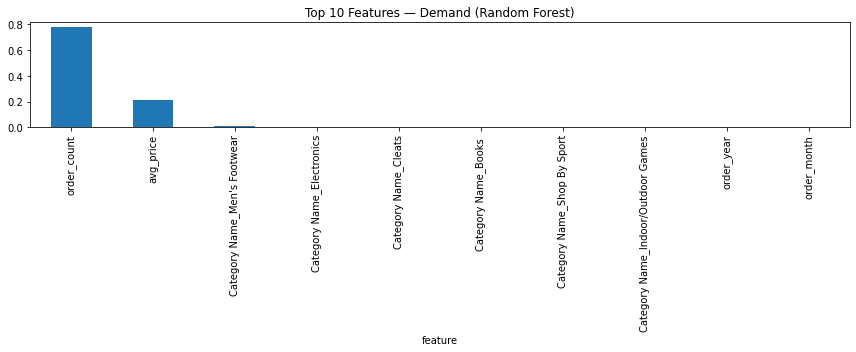

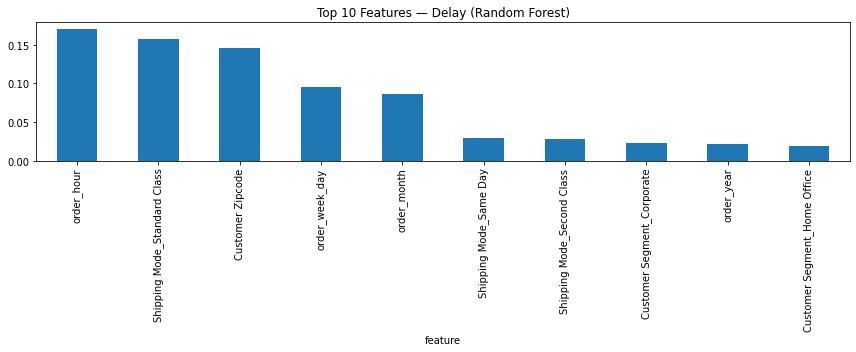

In [54]:

# FEATURE IMPORTANCE


# Demand
feat_imp_demand = pd.DataFrame({
    "feature":    X_demand.columns,
    "importance": best_demand_model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_demand.head(10).plot.bar(
    x="feature", y="importance",
    figsize=(12, 5), legend=False,
    title=f"Top 10 Features — Demand ({best_demand_name})"
)
plt.tight_layout()
plt.show()

# Delay
feat_imp_delay = pd.DataFrame({
    "feature":    X_delay.columns,
    "importance": best_delay_model.feature_importances_
}).sort_values("importance", ascending=False)

feat_imp_delay.head(10).plot.bar(
    x="feature", y="importance",
    figsize=(12, 5), legend=False,
    title=f"Top 10 Features — Delay ({best_delay_name})"
)
plt.tight_layout()
plt.show()

In [55]:

# SAVE MODELS & EXPORT FOR SAP

import joblib
joblib.dump(best_demand_model, "demand_model.pkl")
joblib.dump(best_delay_model,  "delay_model.pkl")

# Demand CSV 
demand_results.to_csv("demand_results.csv", index=False)

# Delay CSV
delay_export = data.loc[X_delay_test.index, delay_context_cols].copy()
delay_export["delay_risk"]     = best_delay_risk
delay_export["delay_decision"] = delay_results["delay_decision"].values
delay_export.to_csv("delay_results.csv", index=False)

print("Models saved ✓")
print("demand_results.csv")
print("delay_results.csv")

Models saved ✓
demand_results.csv
delay_results.csv


In [56]:
print("Demand features:")
for col in X_demand.columns.tolist():
    print(f"  {col}: {X_demand[col].dtype}")

Demand features:
  order_year: int64
  order_month: int64
  avg_price: float64
  order_count: int64
  Category Name_As Seen on  TV!: uint8
  Category Name_Baby : uint8
  Category Name_Baseball & Softball: uint8
  Category Name_Basketball: uint8
  Category Name_Books : uint8
  Category Name_Boxing & MMA: uint8
  Category Name_CDs : uint8
  Category Name_Cameras : uint8
  Category Name_Camping & Hiking: uint8
  Category Name_Cardio Equipment: uint8
  Category Name_Children's Clothing: uint8
  Category Name_Cleats: uint8
  Category Name_Computers: uint8
  Category Name_Consumer Electronics: uint8
  Category Name_Crafts: uint8
  Category Name_DVDs: uint8
  Category Name_Electronics: uint8
  Category Name_Fishing: uint8
  Category Name_Fitness Accessories: uint8
  Category Name_Garden: uint8
  Category Name_Girls' Apparel: uint8
  Category Name_Golf Apparel: uint8
  Category Name_Golf Bags & Carts: uint8
  Category Name_Golf Balls: uint8
  Category Name_Golf Gloves: uint8
  Category Name_Go

In [63]:
print("Delay features:")
for col in X_delay.columns.tolist():
    print(f"  {col}: {X_delay[col].dtype}")

Delay features:
  Customer Zipcode: float64
  order_year: int64
  order_month: int64
  order_week_day: int64
  order_hour: int64
  Shipping Mode_Same Day: uint8
  Shipping Mode_Second Class: uint8
  Shipping Mode_Standard Class: uint8
  Market_Europe: uint8
  Market_LATAM: uint8
  Market_Pacific Asia: uint8
  Market_USCA: uint8
  Order Region_Caribbean: uint8
  Order Region_Central Africa: uint8
  Order Region_Central America: uint8
  Order Region_Central Asia: uint8
  Order Region_East Africa: uint8
  Order Region_East of USA: uint8
  Order Region_Eastern Asia: uint8
  Order Region_Eastern Europe: uint8
  Order Region_North Africa: uint8
  Order Region_Northern Europe: uint8
  Order Region_Oceania: uint8
  Order Region_South America: uint8
  Order Region_South Asia: uint8
  Order Region_South of  USA : uint8
  Order Region_Southeast Asia: uint8
  Order Region_Southern Africa: uint8
  Order Region_Southern Europe: uint8
  Order Region_US Center : uint8
  Order Region_West Africa: uint8